
**Лабораторная работа № 2 · Рекомендательные системы**  
Amazon Reviews категория Video Games

Для пользователя с историей отзывов выбираем десять товаров из раздела видеоигр. Попадание в тесте - товар, на который этот пользователь впервые оставил отзыв в будущем периоде. Данные позволяют наблюдать публикацию отзыва. Время покупки и запуска игры в них не записано.

Источник - исследовательская группа Джулиана Маколи в UC San Diego. В опубликованном наборе 5-core у каждого пользователя и товара есть минимум пять отзывов за весь период.

In [1]:
from collections import Counter
from pathlib import Path
from tempfile import TemporaryDirectory
from urllib.request import urlopen
import gzip
import json
import shutil

import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.ticker import MaxNLocator, PercentFormatter
from scipy.sparse import csr_matrix
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
from threadpoolctl import threadpool_limits

K, N_NEIGHBORS, N_FACTORS, SEED = 10, 40, 32, 42
PAIR = ["user", "item"]
COLORS = {"MostPop": "#a45231", "UserKNN": "#116b63", "SVD": "#555d99"}
plt.rcParams.update({
    "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#303d41", "text.color": "#243339", "figure.dpi": 105,
})

def ru(value, digits=0):
    return f"{value:,.{digits}f}".replace(",", "\u202f").replace(".", ",")

In [2]:
name = "reviews_Video_Games_5.json.gz"
url = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon/categoryFiles/" + name
cache = Path(".cache/lab2_games") / name
local = Path(name)

def read_reviews(path):
    records = []
    with gzip.open(path, "rb") as stream:
        for line in stream:
            row = json.loads(line)
            records.append((row["reviewerID"], row["asin"], row.get("overall"), row["unixReviewTime"]))
    result = pd.DataFrame.from_records(records, columns=[*PAIR, "rating", "day"])
    if len(result) != 231_780:
        raise ValueError(f"Ожидалось 231 780 строк официального файла, прочитано {len(result)}")
    result["day"] = pd.to_datetime(result["day"], unit="s", utc=True).dt.normalize()
    return result

if local.is_file() or cache.is_file():
    events = read_reviews(local if local.is_file() else cache)
else:
    cache.parent.mkdir(parents=True, exist_ok=True)
    with TemporaryDirectory(dir=cache.parent) as directory:
        part = Path(directory) / name
        with urlopen(url, timeout=120) as response, part.open("wb") as out:
            shutil.copyfileobj(response, out, length=1024 * 1024)
        events = read_reviews(part)
        part.replace(cache)

print(f"Прочитано {ru(len(events))} отзывов за {events['day'].min():%d.%m.%Y}–{events['day'].max():%d.%m.%Y}.")

Прочитано 231 780 отзывов за 14.10.1999–22.07.2014.


## 1. Какие оценки ставят пользователи?

Одна запись связывает автора отзыва (`reviewerID`), товар (`asin`), оценку от одной до пяти звёзд (`overall`) и дату публикации (`unixReviewTime`). Идентификаторы товаров сохраняем строками. Текст и заголовок отзыва не участвуют в прогнозе.

In [3]:
rated = events["rating"].dropna()
quality = pd.Series({
    "Отзывов": len(events), "Пользователей": events["user"].nunique(),
    "Товаров": events["item"].nunique(), "Отзывов без оценки": events["rating"].isna().sum(),
    "Пропусков в ID пользователя, ID товара или дате": events[[*PAIR, "day"]].isna().sum().sum(),
    "Оценок вне целой шкалы 1–5": (~rated.isin(range(1, 6))).sum(),
    "Дублей по четырём используемым полям": events.duplicated().sum(),
    "Повторных строк по паре пользователь–товар": events.duplicated(PAIR).sum(),
}, name="Количество")
display(quality.to_frame())

activity = pd.DataFrame({
    "Отзывов у пользователя": events.groupby("user").size().quantile([0, 0.5, 0.99, 1]),
    "Отзывов у товара": events.groupby("item").size().quantile([0, 0.5, 0.99, 1]),
}).T
activity.columns = ["Минимум", "Медиана", "99-й процентиль", "Максимум"]
display(activity.round(1))
assert events[[*PAIR, "day"]].notna().all().all() and rated.isin(range(1, 6)).all()

,Количество
Отзывов,231780
Пользователей,24303
Товаров,10672
Отзывов без оценки,0
"Пропусков в ID пользователя, ID товара или дате",0
Оценок вне целой шкалы 1–5,0
Дублей по четырём используемым полям,0
Повторных строк по паре пользователь–товар,0


,Минимум,Медиана,99-й процентиль,Максимум
Отзывов у пользователя,5.0,7.0,51.0,773.0
Отзывов у товара,5.0,11.0,171.3,802.0


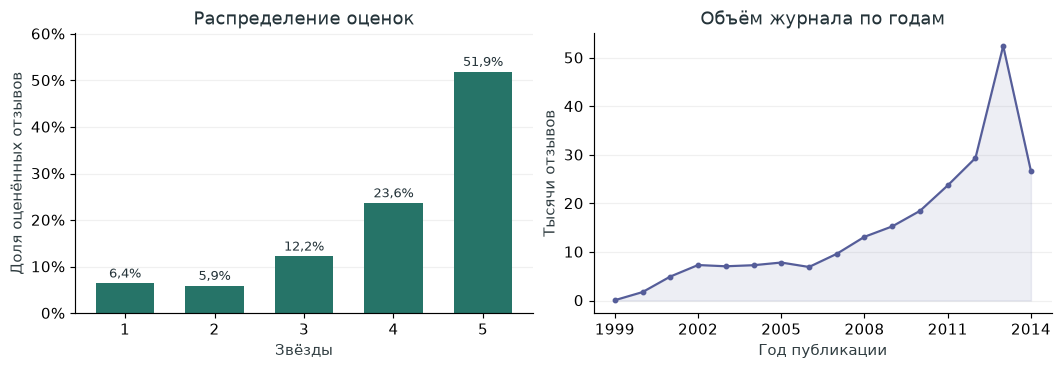

На 4 и 5 звёзд приходится **75,5%** выставленных оценок. Доля отзывов без звёзд — **0,00%** (0 из 231 780). Медиана числа отзывов на товар — **11**, максимум — **802**. Сохраняем товары с большой аудиторией в эксперименте, чтобы измерить вклад популярности. Первый и последний годы на графике неполные.

In [4]:
stars = rated.value_counts(normalize=True).reindex(range(1, 6), fill_value=0).sort_index() * 100
year_counts = events.groupby(events["day"].dt.year).size()
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.4), layout="constrained")
left.bar(stars.index, stars, color="#267468", width=0.65)
left.set(xticks=range(1, 6), xlabel="Звёзды", ylabel="Доля оценённых отзывов",
         title="Распределение оценок")
left.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
for star, share in stars.items():
    left.annotate(ru(share, 1) + "%", (star, share), xytext=(0, 4),
                  textcoords="offset points", ha="center", fontsize=9)
left.set_ylim(0, stars.max() * 1.16)
right.plot(year_counts.index, year_counts / 1000, color="#555d99", marker="o", ms=3)
right.fill_between(year_counts.index, year_counts / 1000, color="#555d99", alpha=0.10)
right.set(xlabel="Год публикации", ylabel="Тысячи отзывов", title="Объём журнала по годам")
right.xaxis.set_major_locator(MaxNLocator(nbins=6, integer=True))
for ax in (left, right):
    ax.grid(axis="y", alpha=0.18)
    ax.set_axisbelow(True)
plt.show()

missing = events["rating"].isna()
display(Markdown(
    f"На 4 и 5 звёзд приходится **{ru(stars.loc[4:5].sum(), 1)}%** выставленных оценок. "
    f"Доля отзывов без звёзд — **{ru(100 * missing.mean(), 2)}%** "
    f"({ru(missing.sum())} из {ru(len(events))}). Медиана числа отзывов на товар — "
    f"**{ru(activity.loc['Отзывов у товара', 'Медиана'])}**, максимум — "
    f"**{ru(activity.loc['Отзывов у товара', 'Максимум'])}**. Сохраняем товары с большой аудиторией "
    "в эксперименте, чтобы измерить вклад популярности. Первый и последний годы на графике неполные."
))

## 2. Помогает ли рейтинг предсказывать будущие отзывы?

Делим журнал по времени. Обучение заканчивается на 80-м процентиле даты, все отзывы одного дня остаются в одной части. В тесте рассматриваем пользователей с историей и хотя бы одним новым товаром. Новый товар — тот, про который пользователь ещё не писал отзыв к дате разделения. Каждая новая пара «пользователь–товар» даёт одну цель независимо от звёзд.

Каталог строим по обучающим отзывам. Товары, впервые появившиеся уже в тесте, тоже входят в число целей. Доля таких случаев показывает, какую часть будущих отзывов модели принципиально не могут предсказать из имеющегося каталога.

In [5]:
cutoff = events["day"].quantile(0.80)
train = events.loc[events["day"].le(cutoff)]
test = events.loc[events["day"].gt(cutoff)]
train_pairs = train.groupby(PAIR, as_index=False, sort=False).agg(rating=("rating", "mean"))
history_index = pd.MultiIndex.from_frame(train_pairs[PAIR])
future = test[PAIR].drop_duplicates()
is_new = ~pd.MultiIndex.from_frame(future).isin(history_index)
targets = future.loc[is_new & future["user"].isin(train_pairs["user"])]

truth = targets.groupby("user")["item"].agg(set)
eval_users = truth.index.to_numpy()
train_users = pd.Index(sorted(train_pairs["user"].unique()))
catalog = pd.Index(sorted(train_pairs["item"].unique()))
cold = ~targets["item"].isin(catalog)
periods = pd.DataFrame({
    "Отзывов": [len(train), len(test)],
    "Доля журнала, %": [100 * len(train) / len(events), 100 * len(test) / len(events)],
    "Первый день": [part["day"].min().date() for part in (train, test)],
    "Последний день": [part["day"].max().date() for part in (train, test)],
}, index=["Обучение", "Тест"])
display(periods.round(2))
display(Markdown(
    f"Пользователей в оценке — **{ru(len(eval_users))}**, новых пар в тесте — "
    f"**{ru(len(targets))}**. Из них **{ru(cold.sum())}** ({ru(100 * cold.mean(), 2)}%) "
    f"приходится на товары за пределами обучающего каталога."
))
assert len(train) + len(test) == len(events) and train["day"].max() < test["day"].min()
assert not pd.MultiIndex.from_frame(targets).isin(history_index).any()
assert len(eval_users) > 0 and int(truth.map(len).sum()) == len(targets)

,Отзывов,"Доля журнала, %",Первый день,Последний день
Обучение,185427,80.0,1999-10-14,2013-08-22
Тест,46353,20.0,2013-08-23,2014-07-22


Пользователей в оценке — **9 038**, новых пар в тесте — **30 900**. Из них **11 726** (37,95%) приходится на товары за пределами обучающего каталога.

### Одна история, два способа задать вес

В бинарной матрице каждый товар с отзывом пользователя получает вес 1. Во взвешенной матрице вес равен $r_{ui}/\bar r$. В числителе стоит среднее выставленных звёзд для одной пары, в знаменателе — средняя оценка по всем отзывам в обучении. Если у пары нет оценки, вес равен 1. Если взаимодействия вообще нет, в матрице стоит 0.

Так отзыв с одной звездой слабее влияет на профиль, чем отзыв с пятью. Оба остаются свидетельством взаимодействия. Для обеих версий фиксируем одни и те же даты, каталог, пользователей и параметры моделей.

In [6]:
mean_rating = train["rating"].mean()
assert np.isfinite(mean_rating) and mean_rating > 0
user_row = train_users.get_indexer(train_pairs["user"])
item_col = catalog.get_indexer(train_pairs["item"])
weights = train_pairs["rating"].div(mean_rating).fillna(1).to_numpy(dtype=np.float32)
shape = (len(train_users), len(catalog))
binary = csr_matrix((np.ones(len(train_pairs), dtype=np.float32), (user_row, item_col)), shape=shape)
weighted = csr_matrix((weights, (user_row, item_col)), shape=shape)
support = np.asarray(binary.sum(axis=0)).ravel()
item_ids = catalog.to_numpy()
eval_rows = train_users.get_indexer(eval_users)
seen_items = train_pairs.groupby("user")["item"].agg(set)
blocked = [binary.indices[binary.indptr[u]:binary.indptr[u + 1]] for u in eval_rows]

display(pd.DataFrame({
    "Отзыв": ["1 звезда", "Без оценки", "5 звёзд"],
    "Бинарный вес": [1.0, 1.0, 1.0],
    "Вес с рейтингом": [1 / mean_rating, 1.0, 5 / mean_rating],
}).set_index("Отзыв").round(3))
display(Markdown(
    f"Средний рейтинг в обучении — **{ru(mean_rating, 3)}**. "
    f"В матрице **{ru(shape[0])} × {ru(shape[1])}** заполнено **{ru(binary.nnz)}** ячеек "
    f"({ru(100 * binary.nnz / (shape[0] * shape[1]), 3)}%)."
))
assert binary.nnz == weighted.nnz == len(train_pairs)
assert np.all(weights[train_pairs["rating"].isna().to_numpy()] == 1)
assert (weights > 0).all() and (eval_rows >= 0).all()

,Бинарный вес,Вес с рейтингом
Отзыв,,
1 звезда,1.0,0.246
Без оценки,1.0,1.000
5 звёзд,1.0,1.232


Средний рейтинг в обучении — **4,059**. В матрице **22 215 × 10 098** заполнено **185 427** ячеек (0,083%).

### Три способа собрать десятку

- **MostPop** ранжирует товары по числу разных авторов обучающих отзывов. Это общий ориентир для сравнения с персональными рекомендациями.
- **UserKNN** находит до 40 ближайших пользователей по косинусному сходству. Балл товара — сумма весов соседских отзывов, умноженных на сходство с соседом. Небольшая добавка `0.000001 × число авторов` отдаёт предпочтение популярным товарам при близких баллах и заполняет список при отсутствии соседских сигналов.
- **SVD** раскладывает разреженную матрицу на 32 фактора (`TruncatedSVD`, `random_state=42`). Оценка кандидата получается при восстановлении строки пользователя из факторов.

Все методы исключают товары из истории пользователя. При равных баллах выше стоит товар с лексикографически меньшим ASIN. В UserKNN равное сходство разрешаем по ID соседа. Для бинарного и взвешенного варианта действуют одни правила.

In [7]:
def top_unseen(scores, excluded):
    scores = np.asarray(scores, dtype=np.float64).copy()
    scores[excluded] = -np.inf
    boundary = np.partition(scores, -K)[-K]
    if not np.isfinite(boundary):
        raise ValueError("В каталоге недостаточно новых товаров для полной десятки")
    candidates = np.flatnonzero(scores >= boundary)
    order = np.argsort(-scores[candidates], kind="stable")
    return candidates[order[:K]]

def personalized(history, batch_size=96):
    unit = normalize(history, norm="l2", axis=1)
    unit_t = unit.T
    svd = TruncatedSVD(n_components=N_FACTORS, random_state=SEED)
    factors = svd.fit_transform(history)
    knn_lists = np.empty((len(eval_users), K), dtype=np.int32)
    svd_lists = np.empty_like(knn_lists)
    for start in range(0, len(eval_rows), batch_size):
        batch = eval_rows[start:start + batch_size]
        similarities = (unit[batch] @ unit_t).tocsr()
        factor_scores = factors[batch] @ svd.components_
        for offset, user in enumerate(batch):
            pos = start + offset
            lo, hi = similarities.indptr[offset:offset + 2]
            ids, sim = similarities.indices[lo:hi], similarities.data[lo:hi]
            useful = (ids != user) & (sim > 0)
            ids, sim = ids[useful], sim[useful]
            near = np.lexsort((ids, -sim))[:N_NEIGHBORS]
            neighbor_scores = np.asarray(history[ids[near]].T @ sim[near]).ravel()
            knn_lists[pos] = top_unseen(neighbor_scores + 1e-6 * support, blocked[pos])
            svd_lists[pos] = top_unseen(factor_scores[offset], blocked[pos])
    return {"UserKNN": knn_lists, "SVD": svd_lists}

most_pop = np.stack([top_unseen(support, excluded) for excluded in blocked])
with threadpool_limits(limits=2, user_api="blas"):
    no_stars = personalized(binary)
    with_stars = personalized(weighted)
recommendations = {"MostPop": most_pop, **with_stars}

In [8]:
truth_by_row = [truth.at[u] for u in eval_users]
history_by_row = [seen_items.at[u] for u in eval_users]
truth_sizes = np.array([len(items) for items in truth_by_row])
discount = 1 / np.log2(np.arange(2, K + 2))
ideal_dcg = np.cumsum(discount)[np.minimum(truth_sizes, K) - 1]

def accuracy(lists):
    assert lists.shape == (len(eval_users), K)
    assert ((lists >= 0) & (lists < len(catalog))).all()
    assert (np.diff(np.sort(lists, axis=1), axis=1) != 0).all()
    predicted = item_ids[lists]
    assert all(seen.isdisjoint(row) for seen, row in zip(history_by_row, predicted))
    hits = np.array([[item in actual for item in row]
                     for actual, row in zip(truth_by_row, predicted)], dtype=np.float64)
    return {
        "Precision@10": float(hits.mean(axis=1).mean()),
        "Recall@10": float((hits.sum(axis=1) / truth_sizes).mean()),
        "NDCG@10": float(((hits @ discount) / ideal_dcg).mean()),
    }

baseline_scores = pd.DataFrame({name: accuracy(rec) for name, rec in no_stars.items()}).T
scores = pd.DataFrame({name: accuracy(rec) for name, rec in recommendations.items()}).T
scores.index.name = baseline_scores.index.name = "Метод"
assert scores.ge(0).all().all() and scores.le(1).all().all()
assert baseline_scores.ge(0).all().all() and baseline_scores.le(1).all().all()

**Precision@10** — доля попаданий среди десяти рекомендаций. **Recall@10** — доля всех новых тестовых товаров пользователя, попавших в десятку. **NDCG@10** даёт попаданию на позиции $j$ вес $1/\log_2(j+1)$ и делит полученную сумму на максимум для этого пользователя. Сначала считаем метрику для каждого пользователя, затем берём среднее. Все новые тестовые отзывы задают бинарную релевантность, включая отзывы с низкой оценкой.

В сравнении ниже Recall и NDCG выражены в процентах, изменение — в процентных пунктах. Знак изменения показывает, помогли ли оценки этой модели на выбранной временной границе.

In [9]:
personal = ["UserKNN", "SVD"]
comparison = {}
for metric in ("Recall@10", "NDCG@10"):
    before = baseline_scores.loc[personal, metric] * 100
    after = scores.loc[personal, metric] * 100
    comparison[(metric, "Без рейтинга, %")] = before
    comparison[(metric, "С рейтингом, %")] = after
    comparison[(metric, "Изменение, п. п.")] = after - before
comparison = pd.DataFrame(comparison)
display(comparison.round(3))

sentences = []
for name in personal:
    change = comparison.loc[name, ("NDCG@10", "Изменение, п. п.")]
    verb = "вырос" if change > 0 else "снизился"
    if np.isclose(change, 0):
        sentences.append(f"У **{name}** NDCG@10 сохранился на прежнем уровне.")
    else:
        sentences.append(f"У **{name}** NDCG@10 {verb} на **{ru(abs(change), 3)} п. п.**")
    changed = (no_stars[name] != with_stars[name]).any(axis=1).sum()
    sentences.append(f"Состав или порядок десятки изменился у {ru(changed)} из {ru(len(eval_users))} пользователей.")
display(Markdown(" ".join(sentences) + " Это измерение на одном временном разбиении."))

Recall@10                                         NDCG@10  \
        Без рейтинга, % С рейтингом, % Изменение, п. п. Без рейтинга, %   
Метод                                                                     
UserKNN           2.695          2.466           -0.229           2.003   
SVD               1.949          1.858           -0.091           1.502   

                                         
        С рейтингом, % Изменение, п. п.  
Метод                                    
UserKNN          1.904           -0.099  
SVD              1.440           -0.062

У **UserKNN** NDCG@10 снизился на **0,099 п. п.** Состав или порядок десятки изменился у 9 034 из 9 038 пользователей. У **SVD** NDCG@10 снизился на **0,062 п. п.** Состав или порядок десятки изменился у 9 037 из 9 038 пользователей. Это измерение на одном временном разбиении.

## 3. Насколько различаются выдачи разных пользователей?

Для **Novelty@10** берём готовые списки одной модели после фильтрации истории. Пусть $N$ — число получивших список пользователей, а $m_i$ — число разных пользователей, которым эта модель показала товар $i$. Новизна одного показа равна $\log_2(N/m_i)$ бит. Усредняем её по десяти позициям, затем по пользователям.

**Coverage@10** показывает, какая доля обучающего каталога хотя бы однажды попала в выдачу. Новизна дополняет охват, поскольку учитывает, скольким пользователям достался каждый рекомендованный товар.

Ручная проверка для двух пользователей. При одинаковых списках каждый товар видят оба человека, поэтому его новизна равна $\log_2(2/2)=0$. В списках **[А, Б]** и **[А, В]** товар А даёт 0 бит, а Б и В — по 1 биту. В среднем получается $(0+1+0+1)/4=0{,}5$ бита.

In [10]:
def novelty_at_k(lists):
    n_users = len(lists)
    recipients = Counter(item for row in lists for item in set(row))
    bits = {item: np.log2(n_users / count) for item, count in recipients.items()}
    return float(np.mean([np.mean([bits[item] for item in row]) for row in lists]))

examples = [
    ("[А, Б] и [А, Б]", [["А", "Б"], ["А", "Б"]], 0.0),
    ("[А, Б] и [А, В]", [["А", "Б"], ["А", "В"]], 0.5),
]
checks = []
for label, lists, expected in examples:
    value = novelty_at_k(lists)
    assert np.isclose(value, expected)
    checks.append((label, expected, value))
display(pd.DataFrame(checks, columns=["Два списка", "Вручную, бит", "Функция, бит"]).set_index("Два списка"))

results = scores.copy()
for name, lists in recommendations.items():
    results.loc[name, "Novelty@10"] = novelty_at_k(lists)
    results.loc[name, "Coverage@10"] = np.unique(lists).size / len(catalog)
assert results["Novelty@10"].between(0, np.log2(len(eval_users))).all()
assert results["Coverage@10"].between(0, 1).all()
display(results.round(5))

,"Вручную, бит","Функция, бит"
Два списка,,
"[А, Б] и [А, Б]",0.0,0.0
"[А, Б] и [А, В]",0.5,0.5


,Precision@10,Recall@10,NDCG@10,Novelty@10,Coverage@10
Метод,,,,,
MostPop,0.00325,0.00867,0.00829,0.08752,0.00168
UserKNN,0.00830,0.02466,0.01904,7.31365,0.61339
SVD,0.00678,0.01858,0.01440,3.98928,0.04159


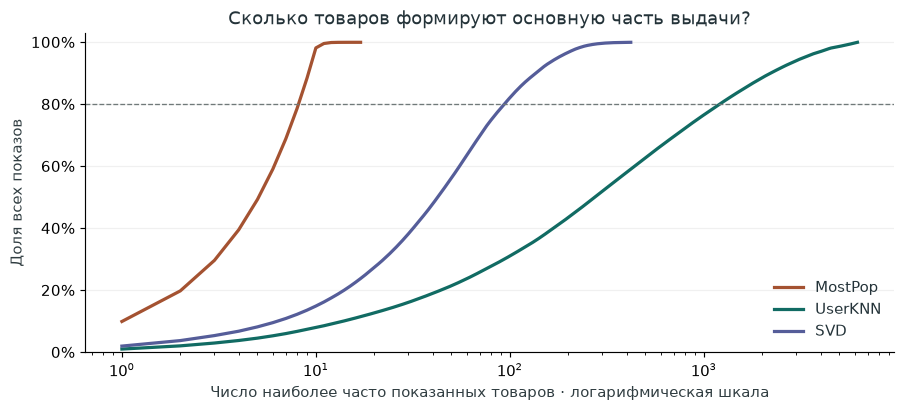

**Что видно из выдачи.** В MostPop **9** товаров набирают 80% показов, в UserKNN — **1 203**, в SVD — **94**. Новизна MostPop после исключения истории составляет **0,088 бит**. Фильтр заменяет уже оценённые товары следующими в рейтинге популярности.

**Итог эксперимента.** Среди MostPop и двух персональных моделей с учётом звёзд лучший NDCG@10 у **UserKNN** (**0,01904**). Эта модель находит в среднем **2,47%** новых тестовых товаров пользователя. Наибольший охват у **UserKNN** — **61,34%** каталога. Таблица сравнения с бинарной историей выше показывает отдельный вклад звёзд.

In [11]:
fig, ax = plt.subplots(figsize=(8.5, 3.8), layout="constrained")
items_for_80 = {}
for name, lists in recommendations.items():
    counts = np.bincount(lists.ravel(), minlength=len(catalog))
    freq = np.sort(counts[counts > 0])[::-1]
    cumulative = np.cumsum(freq) / freq.sum()
    items_for_80[name] = int(np.searchsorted(cumulative, 0.8) + 1)
    ax.plot(np.arange(1, len(freq) + 1), cumulative * 100,
            color=COLORS[name], linewidth=2.2, label=name)
ax.axhline(80, linestyle="--", color="#707979", linewidth=0.9)
ax.set(xscale="log", ylim=(0, 103), xlabel="Число наиболее часто показанных товаров · логарифмическая шкала",
       ylabel="Доля всех показов", title="Сколько товаров формируют основную часть выдачи?")
ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
ax.grid(axis="y", alpha=0.18)
ax.legend(frameon=False)
plt.show()

best_rank = results["NDCG@10"].idxmax()
widest = results["Coverage@10"].idxmax()
display(Markdown(
    f"**Что видно из выдачи.** В MostPop **{ru(items_for_80['MostPop'])}** товаров набирают 80% показов, "
    f"в UserKNN — **{ru(items_for_80['UserKNN'])}**, в SVD — **{ru(items_for_80['SVD'])}**. "
    f"Новизна MostPop после исключения истории составляет **{ru(results.at['MostPop', 'Novelty@10'], 3)} бит**. "
    "Фильтр заменяет уже оценённые товары следующими в рейтинге популярности."
))
display(Markdown(
    f"**Итог эксперимента.** Среди MostPop и двух персональных моделей с учётом звёзд лучший NDCG@10 у **{best_rank}** "
    f"(**{ru(results.at[best_rank, 'NDCG@10'], 5)}**). Эта модель находит в среднем "
    f"**{ru(100 * results.at[best_rank, 'Recall@10'], 2)}%** новых тестовых товаров пользователя. "
    f"Наибольший охват у **{widest}** — **{ru(100 * results.at[widest, 'Coverage@10'], 2)}%** каталога. "
    "Таблица сравнения с бинарной историей выше показывает отдельный вклад звёзд."
))